# Frontière efficiente sur 4 ETF : que vaut un 60/40 ?

Le notebook 07 construisait un portefeuille 60 % actions / 40 % obligations, une allocation fixée par convention. Celui-ci se demande si cette allocation est efficiente : existe-t-il, avec les mêmes ETF, un portefeuille offrant plus de rendement pour le même risque, ou le même rendement pour moins de risque ?

Méthode : frontière efficiente de Markowitz, portefeuille de variance minimale (GMV), portefeuille de Sharpe maximal (MSR) et portefeuille équipondéré, d'après la semaine 2 du cours *Introduction to Portfolio Construction and Analysis with Python* (EDHEC Business School).

Données : `data/actions_obligations.csv`, 659 séances du 19 février 2024 au 25 septembre 2026 — trois ETF STOXX Europe 600 (MEUD.PA, EXSA.DE, ETZ.PA) et un ETF d'emprunts d'État de la zone euro (IEGA.AS).

Auteur : KOULEKPOTO Yao Eloge Crédo — novembre 2026

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

## 1. Fonctions de construction de portefeuille

Fonctions adaptées du cours EDHEC. Les rendements et la covariance sont tous deux annualisés, pour que les deux axes du graphique soient dans la même unité.

In [14]:
# Annualized return and volatility from daily returns
def annualize_rets(r, periods_per_year=252):
    return (1 + r).prod() ** (periods_per_year / r.shape[0]) - 1

def annualize_vol(r, periods_per_year=252):
    return r.std() * np.sqrt(periods_per_year)

# Portfolio return and volatility for a given set of weights
def portfolio_return(weights, er):
    return weights @ er

def portfolio_vol(weights, cov):
    return np.sqrt(weights @ cov @ weights)

# Weights of the minimum-volatility portfolio for a target return
def minimize_vol(target_return, er, cov):
    n = er.shape[0]
    bounds = ((0.0, 1.0),) * n
    constraints = (
        {"type": "eq", "fun": lambda w: np.sum(w) - 1},
        {"type": "eq", "fun": lambda w: portfolio_return(w, er) - target_return},
    )
    res = minimize(portfolio_vol, np.repeat(1 / n, n), args=(cov,),
                   method="SLSQP", bounds=bounds, constraints=constraints)
    return res.x

# Weights of the maximum Sharpe ratio portfolio
def msr(riskfree_rate, er, cov):
    n = er.shape[0]
    bounds = ((0.0, 1.0),) * n
    constraints = ({"type": "eq", "fun": lambda w: np.sum(w) - 1},)
    def neg_sharpe(w):
        return -(portfolio_return(w, er) - riskfree_rate) / portfolio_vol(w, cov)
    res = minimize(neg_sharpe, np.repeat(1 / n, n),
                   method="SLSQP", bounds=bounds, constraints=constraints)
    return res.x

# Weights of the global minimum variance portfolio (MSR with equal expected returns)
def gmv(cov):
    n = cov.shape[0]
    return msr(0, np.repeat(1.0, n), cov)

## 2. Données et paramètres

In [15]:
prices = pd.read_csv("data/actions_obligations.csv", index_col=0, parse_dates=True)
returns = prices.pct_change().dropna()

er = annualize_rets(returns)       # annualized expected returns
cov = returns.cov() * 252          # annualized covariance matrix
vol = annualize_vol(returns)
rf = 0.02                          # risk-free rate, same assumption as notebook 06

pd.DataFrame({"Rendement annualisé": er, "Volatilité annualisée": vol}).style.format("{:.2%}")

,Rendement annualisé,Volatilité annualisée
ETZ.PA,13.57%,13.15%
EXSA.DE,13.83%,13.15%
MEUD.PA,14.00%,13.28%
IEGA.AS,0.43%,4.55%


Les trois ETF actions affichent des rendements et des volatilités quasi identiques, autour de 13,6 à 14,0 % de rendement pour 13,2 % de volatilité : ils répliquent le même indice. L'ETF obligataire rapporte 0,43 % par an pour 4,55 % de volatilité, moins que le taux sans risque retenu de 2 %.

## 3. Trois portefeuilles de référence

- **GMV** : le portefeuille le moins risqué possible. Il n'utilise que la matrice de covariance.
- **MSR** : le portefeuille au meilleur ratio de Sharpe, avec un taux sans risque de 2 %. Il utilise les rendements attendus, estimés ici sur le passé.
- **Équipondéré** : 25 % sur chaque ETF, sans aucune estimation.
- **60/40** : le portefeuille du notebook 07, 60 % MEUD.PA et 40 % IEGA.AS.

In [16]:
n = len(er)
w_gmv = gmv(cov)
w_msr = msr(rf, er, cov)
w_ew = np.repeat(1 / n, n)

# 60/40 built by column name, so the order of the columns does not matter
w_6040 = pd.Series(0.0, index=er.index)
w_6040["MEUD.PA"] = 0.6
w_6040["IEGA.AS"] = 0.4
w_6040 = w_6040.values

weights = pd.DataFrame({"GMV": w_gmv, "MSR": w_msr, "Équipondéré": w_ew, "60/40": w_6040},
                       index=er.index)
weights.style.format("{:.1%}")

,GMV,MSR,Équipondéré,60/40
ETZ.PA,2.3%,0.0%,25.0%,0.0%
EXSA.DE,0.0%,9.8%,25.0%,0.0%
MEUD.PA,0.0%,90.2%,25.0%,60.0%
IEGA.AS,97.7%,0.0%,25.0%,40.0%


In [17]:
# Return, volatility and Sharpe ratio of each portfolio
summary = pd.DataFrame({
    name: {"Rendement": portfolio_return(w, er),
           "Volatilité": portfolio_vol(w, cov)}
    for name, w in weights.items()
}).T
summary["Sharpe (2 %)"] = (summary["Rendement"] - rf) / summary["Volatilité"]
summary.style.format({"Rendement": "{:.2%}", "Volatilité": "{:.2%}", "Sharpe (2 %)": "{:.2f}"})

,Rendement,Volatilité,Sharpe (2 %)
GMV,0.73%,4.54%,-0.28
MSR,13.99%,13.26%,0.90
Équipondéré,10.46%,10.25%,0.83
60/40,8.57%,8.67%,0.76


Les quatre portefeuilles occupent des positions très différentes.

- Le **GMV** place 97,7 % dans l'ETF obligataire : 4,54 % de volatilité, mais un rendement de 0,73 % et un ratio de Sharpe négatif. Le moins risqué n'est pas le plus rentable par unité de risque.
- Le **MSR** ne contient aucune obligation : 90,2 % MEUD.PA et 9,8 % EXSA.DE, pour un Sharpe de 0,90. Sur cette période, l'obligation a rapporté moins que le taux sans risque ; l'optimiseur la juge inutile.
- L'**équipondéré** atteint un Sharpe de 0,83 sans aucune estimation des rendements, proche du MSR.
- Le **60/40** offre 8,57 % de rendement pour 8,67 % de volatilité, avec un Sharpe de 0,76.

## 4. La frontière efficiente

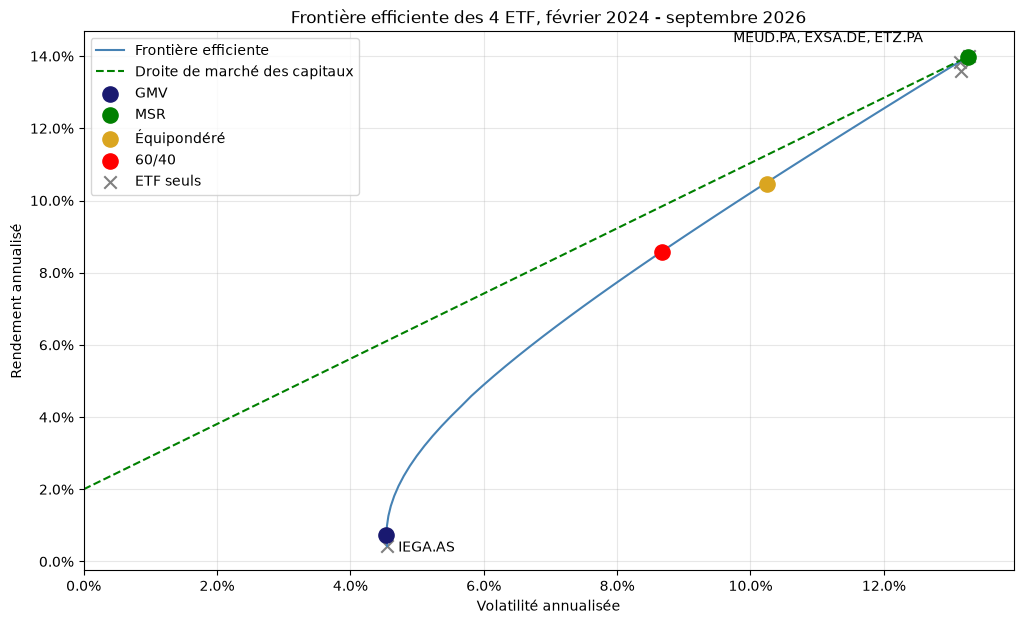

In [18]:
# Efficient frontier: minimum volatility for each target return
targets = np.linspace(er.min(), er.max(), 50)
frontier_w = [minimize_vol(t, er, cov) for t in targets]
frontier = pd.DataFrame({
    "Rendement": [portfolio_return(w, er) for w in frontier_w],
    "Volatilité": [portfolio_vol(w, cov) for w in frontier_w],
})

fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(frontier["Volatilité"], frontier["Rendement"], color="steelblue", label="Frontière efficiente")

# Capital market line from the risk-free rate to the MSR portfolio
ax.plot([0, summary.loc["MSR", "Volatilité"]], [rf, summary.loc["MSR", "Rendement"]],
        color="green", linestyle="--", label="Droite de marché des capitaux")

markers = {"GMV": "midnightblue", "MSR": "green", "Équipondéré": "goldenrod", "60/40": "red"}
for name, color in markers.items():
    ax.scatter(summary.loc[name, "Volatilité"], summary.loc[name, "Rendement"],
               color=color, s=120, zorder=5, label=name)

# Individual ETFs
ax.scatter(vol, er, color="grey", marker="x", s=80, label="ETF seuls")
ax.annotate("IEGA.AS", (vol["IEGA.AS"], er["IEGA.AS"]), textcoords="offset points", xytext=(8, -4))
ax.annotate("MEUD.PA, EXSA.DE, ETZ.PA", (vol["MEUD.PA"], er["MEUD.PA"]),
            textcoords="offset points", xytext=(-170, 10))
ax.set_xlim(left=0)
ax.set_title("Frontière efficiente des 4 ETF, février 2024 - septembre 2026")
ax.set_xlabel("Volatilité annualisée")
ax.set_ylabel("Rendement annualisé")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.grid(alpha=0.3)
ax.legend()
fig.savefig("images/frontiere_efficiente.png", dpi=150, bbox_inches="tight")

Le 60/40 se situe sur la frontière efficiente : à volatilité égale, aucun mélange de ces quatre ETF ne rapporte nettement plus. L'allocation fixée par convention au notebook 07 n'est donc pas dominée. Elle ne correspond simplement pas au portefeuille tangent : le MSR obtient un meilleur Sharpe en éliminant l'obligation, ce qui tient au rendement très faible de celle-ci sur la période étudiée.

Les trois ETF actions se superposent en haut à droite, et l'ETF obligataire forme l'extrémité basse de la frontière : avec des fonds aussi semblables, la frontière se résume presque à un mélange entre deux actifs.

## 5. La fragilité du MSR

Le MSR dépend des rendements attendus, estimés sur 2,6 ans. Pour mesurer sa sensibilité à cette estimation, on retire 0,5 point au rendement annualisé de MEUD.PA, un écart du même ordre que la différence de frais entre les trois ETF actions, et on recalcule les poids.

In [19]:
er_bis = er.copy()
er_bis["MEUD.PA"] -= 0.005
w_msr_bis = msr(rf, er_bis, cov)

pd.DataFrame({"MSR initial": w_msr, "MSR avec MEUD.PA −0,5 pt": w_msr_bis,
              "GMV": w_gmv}, index=er.index).style.format("{:.1%}")

,MSR initial,"MSR avec MEUD.PA −0,5 pt",GMV
ETZ.PA,0.0%,0.0%,2.3%
EXSA.DE,9.8%,100.0%,0.0%
MEUD.PA,90.2%,0.0%,0.0%
IEGA.AS,0.0%,0.0%,97.7%


Une baisse de 0,5 point du rendement estimé de MEUD.PA suffit à faire basculer le MSR de 90,2 % MEUD.PA à 100 % EXSA.DE. Une modification minime d'une seule estimation déplace 90 points d'allocation.

Le GMV, qui n'utilise pas les rendements attendus, ne change pas. C'est la limite de l'optimisation de Markowitz mise en évidence par le cours EDHEC : l'optimiseur amplifie les erreurs d'estimation des rendements, et concentre l'allocation sur l'actif dont le rendement passé a été le plus favorable.

## Conclusion

Le portefeuille 60/40 du notebook 07 est efficient : avec ces quatre ETF, il n'existe pas de mélange offrant nettement plus de rendement pour le même risque.

Le portefeuille de Sharpe maximal fait mieux sur le papier, avec un Sharpe de 0,90 contre 0,76, mais il ne contient aucune obligation et repose entièrement sur des rendements estimés sur 2,6 ans. Une variation de 0,5 point d'une seule estimation renverse sa composition. Il n'est pas utilisable tel quel.

Le portefeuille équipondéré atteint un Sharpe de 0,83 sans aucune estimation des rendements, ce qui illustre pourquoi les règles simples résistent souvent mieux que l'optimisation hors échantillon.

### Limites

- Fenêtre de 2,6 ans marquée par une forte hausse des actions et un rendement obligataire très faible : sur une période de baisse des marchés, le MSR inclurait probablement l'obligation.
- Trois ETF actions sur le même indice : l'univers se réduit en pratique à deux classes d'actifs.
- Pas de frais de transaction ni de rééquilibrage dans l'optimisation.
- Taux sans risque fixé à 2 % sur toute la période.